In [42]:
import pandas as pd
import matplotlib.pyplot as plt

crime = pd.read_csv("CrimeData.csv", sep=",")
crime.sample(10)


crimePerNeighborhood= dict()
numCrimeList= []

#filter out the neighborhoods that are just places outside of the city
crime= crime[crime['INCIDENTNEIGHBORHOOD'].str.contains("Outside", na=False)==False]
crime= crime[crime['INCIDENTNEIGHBORHOOD'].str.contains("Boro", na=False)==False]

#create a list of all the different neighborhoods so the number of crimes reported in each can be counted
neighborhoodList= crime['INCIDENTNEIGHBORHOOD'].dropna().unique()
#print(neighborhoodList)
for neighborhood in neighborhoodList:
    query_mask= crime['INCIDENTNEIGHBORHOOD'].str.contains(neighborhood, na=False)
    sepNeighborhoodList= crime[query_mask]

    numCrimeList.append(len(sepNeighborhoodList))
    crimePerNeighborhood[len(sepNeighborhoodList)]= neighborhood
    
    print(neighborhood)
    #print(neighborhood + ": " +str(len(sepNeighborhoodList)))

numCrimeList.sort()
print("10 Lowest Crime Neighborhoods")
i=0
while i<10:
    print(crimePerNeighborhood[numCrimeList[i]] + ": "+ str(numCrimeList[i]))
    i+=1
print("\n10 Highest Crime Neighborhoods")
i= len(numCrimeList)-1
while i>len(numCrimeList)-10:
    print(crimePerNeighborhood[numCrimeList[i]] + ": "+ str(numCrimeList[i]))
    i-=1

North Shore
Upper Lawrenceville
Northview Heights
Golden Triangle/Civic Arena
South Side Flats
Elliott
Homewood North
South Side Slopes
Carrick
South Oakland
Bloomfield
Beechview
Bluff
Strip District
Mount Washington
East Carnegie
Crafton Heights
Marshall-Shadeland
East Liberty
East Allegheny
Friendship
Arlington
Central Northside
Spring Hill-City View
Brighton Heights
Westwood
East Hills
Brookline
South Shore
Lower Lawrenceville
Bedford Dwellings
Troy Hill-Herrs Island
Central Oakland
Garfield
West End
West Oakland
Central Lawrenceville
Lincoln-Lemington-Belmar
Sheraden
Beltzhoover
Squirrel Hill South
North Oakland
Allentown
Perry North
Homewood South
Shadyside
Manchester
Squirrel Hill North
Regent Square
Homewood West
Allegheny Center
Highland Park
Middle Hill
Overbrook
Hazelwood
Greenfield
Morningside
Knoxville
Point Breeze
Duquesne Heights
Perry South
California-Kirkbride
Banksville
Point Breeze North
Bon Air
Polish Hill
Lincoln Place
Fineview
Spring Garden
Larimer
Esplen
Terrace V

Best: The least number of crimes reported in a neighborhood

The best overall is **Troy Hill-Herrs Island**

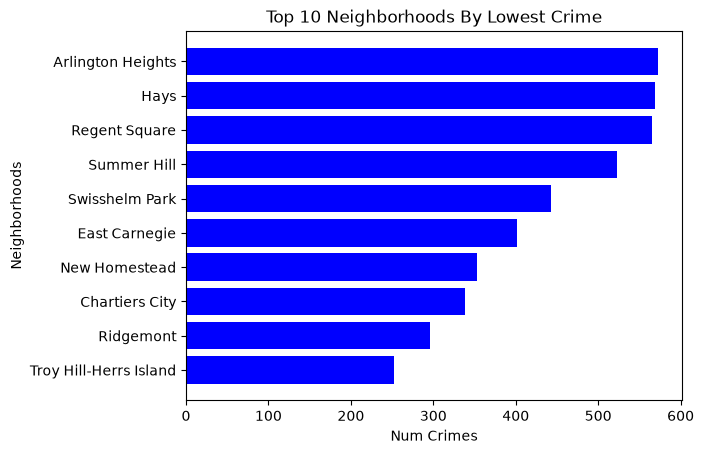

In [43]:
topTenNeighborhoods= []
i=0
while i<10:
    topTenNeighborhoods.append(crimePerNeighborhood[numCrimeList[i]])
    i+=1

values= list(numCrimeList[:10])
neighborhoods= list(topTenNeighborhoods)

plt.barh(neighborhoods,values, color='blue')
plt.xlabel('Num Crimes')
plt.ylabel('Neighborhoods')
plt.title('Top 10 Neighborhoods By Lowest Crime')
plt.show()

93


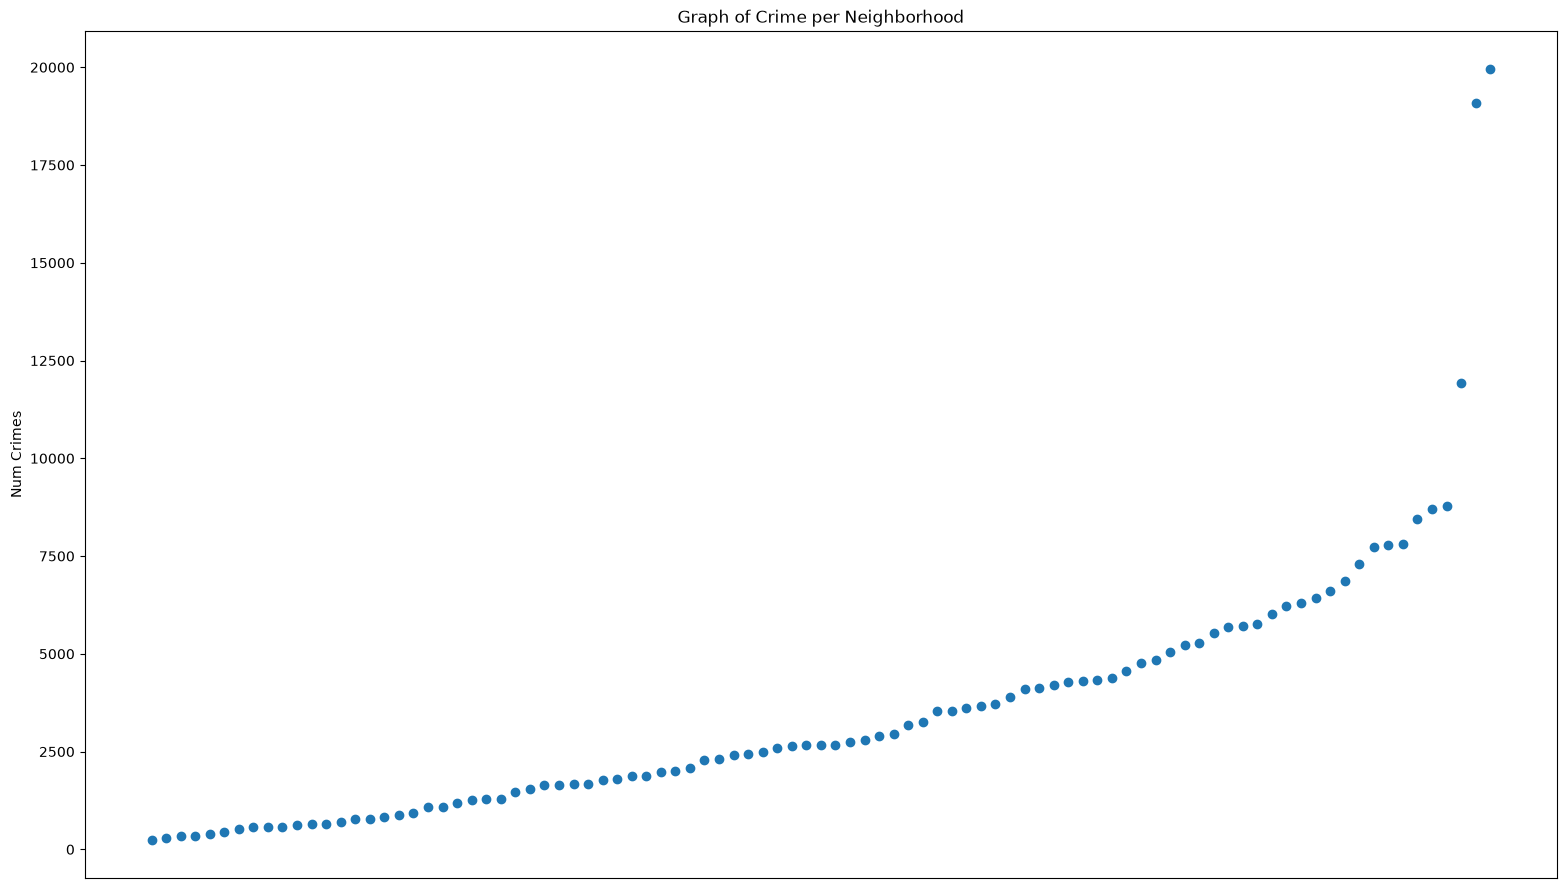

In [44]:
x= []
allNeighborhoods=[]
i=0
while i<len(numCrimeList):
    x.append(i)
    allNeighborhoods.append(crimePerNeighborhood[numCrimeList[i]])
    i+=1

y=numCrimeList
print(len(numCrimeList))

plt.figure(figsize=(19,11))
plt.scatter(x,y)
plt.ylabel('Num Crimes')
plt.title('Graph of Crime per Neighborhood')
plt.gca().xaxis.set_visible(False)

plt.show()